# Department-Based Active Questioning System

This notebook demonstrates the department-based active questioning approach for medical diagnosis.

## Overview

Instead of asking questions to identify specific diseases, this system:
1. Aggregates disease probabilities by hospital department (SUM method)
2. Asks questions to discriminate between DEPARTMENTS
3. Directs patients to the correct department when confidence >85%

## Key Differences from Disease-Based Approach

| Aspect | Disease-Based | Department-Based |
|--------|---------------|------------------|
| Prediction Target | 577 diseases | 26 departments |
| Aggregation | Individual disease probabilities | SUM of diseases in same department |
| Questions Focus | Distinguish between similar diseases | Distinguish between departments |
| Clinical Goal | Specific disease diagnosis | Department referral |
| Confidence Threshold | Disease probability >85% | Department probability >85% |

---

## Setup and Imports

In [1]:
import sys
import os
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to path
BASE_DIR = Path.cwd().parent.parent
sys.path.insert(0, str(BASE_DIR))

from app_v2.services.ann_service import ANNService
from app_v2.services.department_questioning import DepartmentBasedQuestioningEngine

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print(" Imports successful")
print(f" Project root: {BASE_DIR}")

 Imports successful
 Project root: /Users/dinhquanghien/Desktop/Report


## Load Models and Data

In [2]:
# File paths
MODEL_PATH = BASE_DIR / "building_ANN/models/pytorch/best_model.pth"
LABEL_ENCODER_PATH = BASE_DIR / "building_ANN/models/pytorch/label_encoder.pkl"
TRAIN_DATA_PATH = BASE_DIR / "building_ANN/data/processed/common/train.csv"
CONFUSION_MATRIX_PATH = BASE_DIR / "building_ANN/data/evaluation/most_confused_pairs.csv"
DEPT_MAP_PATH = BASE_DIR / "building_ANN/utils/department_map_577.json"

# Load department map
print(" Loading department map...")
with open(DEPT_MAP_PATH, 'r', encoding='utf-8') as f:
    dept_map = json.load(f)

print(f" Loaded department map: {len(dept_map)} diseases mapped")

# Count departments
unique_depts = set(dept_map.values())
print(f" Total departments: {len(unique_depts)}")
print(f"\nDepartments: {sorted(unique_depts)}")

 Loading department map...
 Loaded department map: 577 diseases mapped
 Total departments: 26

Departments: ['Chấn thương chỉnh hình', 'Cơ xương khớp', 'Cấp cứu', 'Cấp cứu / Nội hô hấp', 'Da liễu', 'Huyết học', 'Khám tổng quát', 'Mắt', 'Nam khoa', 'Ngoại tổng quát', 'Ngoại tổng quát / Cấp cứu', 'Nội hô hấp', 'Nội tiết', 'Răng Hàm Mặt', 'Sản phụ khoa', 'Sản phụ khoa / Nội tiết', 'Tai Mũi Họng', 'Thần kinh', 'Thận – Tiết niệu', 'Tim mạch', 'Tiêu hoá', 'Tiêu hoá – Gan mật', 'Truyền nhiễm', 'Truyền nhiễm / Da liễu', 'Tâm thần', 'Ung bướu']


In [3]:
# Initialize ANN Service with department-based questioning
print(" Initializing ANN Service with department-based questioning...")

ann_service = ANNService(
    model_path=str(MODEL_PATH),
    label_encoder_path=str(LABEL_ENCODER_PATH),
    train_data_path=str(TRAIN_DATA_PATH),
    confusion_matrix_path=str(CONFUSION_MATRIX_PATH) if CONFUSION_MATRIX_PATH.exists() else None,
    department_map=dept_map  # Enable department-based questioning
)

print(" ANN Service initialized successfully")
print(f" Model: {ann_service.model.__class__.__name__}")
print(f" Diseases: {len(ann_service.label_encoder.classes_)}")
print(f" Symptoms: {len(ann_service.symptom_columns)}")
print(f" Department questioning: {'Enabled' if ann_service.dept_questioning_engine else 'Disabled'}")

 Initializing ANN Service with department-based questioning...
 ANN Service initialized successfully
 Model: ANNDiseaseClassifier
 Diseases: 577
 Symptoms: 377
 Department questioning: Enabled


---
## Test Scenario: Patient with Neurological Symptoms

We'll simulate a patient presenting with symptoms commonly associated with neurological conditions.

In [4]:
# Define initial symptoms
initial_symptoms = [
    "đau đầu",
    "sốt cao",
    "buồn nôn",
    "mệt mỏi"
]

print(" Initial symptoms reported by patient:")
for i, symptom in enumerate(initial_symptoms, 1):
    print(f"   {i}. {symptom}")

 Initial symptoms reported by patient:
   1. đau đầu
   2. sốt cao
   3. buồn nôn
   4. mệt mỏi


---
## Step 1: Initial Disease Prediction (ANN Model)

In [5]:
# Get initial disease prediction
prediction = ann_service.predict_from_symptoms(initial_symptoms, top_k=15)

print(f" Top disease: {prediction.top_disease}")
print(f" Confidence: {prediction.top_confidence*100:.2f}% ({prediction.confidence_category})")
print(f" Needs questioning: {'YES' if prediction.needs_questioning else 'NO'}")
print(f"\n Top 15 Disease Predictions:")


# Create DataFrame for better display
predictions_df = pd.DataFrame([
    {
        'Rank': i,
        'Disease': disease,
        'Probability': f"{probability*100:.2f}%",
        'Department': dept_map.get(disease, 'Khám tổng quát')
    }
    for i, (disease, probability) in enumerate(prediction.top_k_predictions[:15], 1)
])

predictions_df

Unknown symptoms (will be ignored): ['sốt cao', 'mệt mỏi']


 Top disease: ngộ độc khí carbon monoxide
 Confidence: 39.25% (LOW)
 Needs questioning: YES

 Top 15 Disease Predictions:


,Rank,Disease,Probability,Department
0,1,ngộ độc khí carbon monoxide,39.25%,Khám tổng quát
1,2,đau đầu sau khi chọc dịch não tủy,14.04%,Thần kinh
2,3,viêm màng não,9.79%,Thần kinh
3,4,đau đầu do căng thẳng,8.26%,Khám tổng quát
4,5,chứng đau nửa đầu,4.94%,Thần kinh
5,6,bệnh Meniere,3.93%,Tai Mũi Họng
6,7,xuất huyết não,2.27%,Cấp cứu
7,8,phản ứng thuốc,2.12%,Khám tổng quát
8,9,viêm mê đạo,2.09%,Khám tổng quát
9,10,cơn đau dọc vị trí kịch phát lành tính (bppv),1.72%,Khám tổng quát


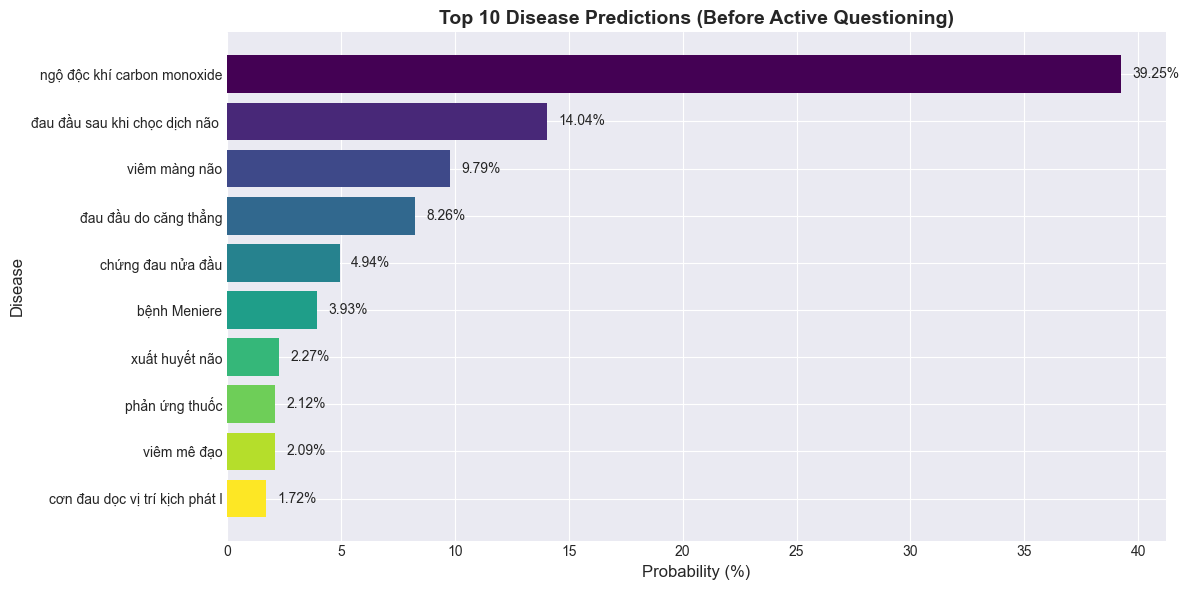

In [6]:
# Visualize disease predictions
fig, ax = plt.subplots(figsize=(12, 6))

diseases = [disease[:30] for disease, _ in prediction.top_k_predictions[:10]] # Truncate long names
probs = [probability*100 for _, probability in prediction.top_k_predictions[:10]]

colors = plt.cm.viridis(np.linspace(0, 1, 10))
bars = ax.barh(diseases, probs, color=colors)

ax.set_xlabel('Probability (%)', fontsize=12)
ax.set_ylabel('Disease', fontsize=12)
ax.set_title('Top 10 Disease Predictions (Before Active Questioning)', fontsize=14, fontweight='bold')
ax.invert_yaxis()

# Add value labels
for bar, prob in zip(bars, probs):
    ax.text(prob + 0.5, bar.get_y() + bar.get_height()/2, 
            f'{prob:.2f}%', va='center', fontsize=10)

plt.tight_layout()
plt.show()

---
## Step 2: Department Aggregation

Now we aggregate disease probabilities by department using the **SUM method**:

$$P(\text{department}) = \sum_{\text{disease} \in \text{department}} P(\text{disease})$$

In [6]:
# Start department-based questioning session
session_id = "demo_session_001"

session, first_question = ann_service.start_department_questioning_session(
    session_id=session_id,
    initial_symptoms=initial_symptoms
)

print(f" Department Aggregation Results:")
print(f"   Total departments identified: {len(session.current_departments)}")
print(f"   Initial confidence: {session.initial_confidence*100:.2f}%")
print(f"   Strategy: {session.strategy}")
print(f"   Max questions: {session.max_questions}")

Unknown symptoms (will be ignored): ['sốt cao', 'mệt mỏi']


 Department Aggregation Results:
   Total departments identified: 26
   Initial confidence: 57.01%
   Strategy: hybrid
   Max questions: 10


In [7]:
# Display department probabilities
print(f"\n Top 10 Departments (Aggregated from Diseases):")

dept_data = []
for i, dept_hyp in enumerate(session.current_departments[:10], 1):
    dept_data.append({
        'Rank': i,
        'Department': dept_hyp.department_name,
        'Probability': f"{dept_hyp.probability*100:.2f}%",
        'Contributing Diseases': len(dept_hyp.contributing_diseases),
        'Top Disease': dept_hyp.contributing_diseases[0][0] if dept_hyp.contributing_diseases else 'N/A',
        'Top Disease Prob': f"{dept_hyp.contributing_diseases[0][1]*100:.2f}%" if dept_hyp.contributing_diseases else 'N/A'
    })

dept_df = pd.DataFrame(dept_data)
dept_df


 Top 10 Departments (Aggregated from Diseases):


,Rank,Department,Probability,Contributing Diseases,Top Disease,Top Disease Prob
0,1,Khám tổng quát,57.01%,198,ngộ độc khí carbon monoxide,39.25%
1,2,Thần kinh,29.46%,36,đau đầu sau khi chọc dịch não tủy,14.04%
2,3,Tiêu hoá,4.80%,25,viêm dạ dày,1.46%
3,4,Tai Mũi Họng,3.95%,25,bệnh Meniere,3.93%
4,5,Cấp cứu,2.28%,2,xuất huyết não,2.27%
5,6,Ngoại tổng quát / Cấp cứu,0.99%,1,tắc ruột,0.99%
6,7,Sản phụ khoa,0.75%,35,các vấn đề trong thai kỳ,0.70%
7,8,Tiêu hoá – Gan mật,0.17%,11,viêm gan do độc tố,0.15%
8,9,Tim mạch,0.13%,31,tăng huyết áp ác tính,0.12%
9,10,Mắt,0.12%,18,viêm mống mắt thể mi,0.12%


In [8]:
# Show contributing diseases for top 3 departments
print("\n Detailed Breakdown - Top 3 Departments:")
print("="*80)

for i, dept_hyp in enumerate(session.current_departments[:3], 1):
    print(f"\n{i}. {dept_hyp.department_name}: {dept_hyp.probability*100:.2f}%")
    print(f"   Contributing diseases ({len(dept_hyp.contributing_diseases)}):")
    
    for j, (disease, prob) in enumerate(dept_hyp.contributing_diseases[:5], 1):
        print(f"      {j}. {disease}: {prob*100:.2f}%")
    
    if len(dept_hyp.contributing_diseases) > 5:
        print(f"      ... and {len(dept_hyp.contributing_diseases) - 5} more diseases")
    print("-"*80)


 Detailed Breakdown - Top 3 Departments:

1. Khám tổng quát: 57.01%
   Contributing diseases (198):
      1. ngộ độc khí carbon monoxide: 39.25%
      2. đau đầu do căng thẳng: 8.26%
      3. phản ứng thuốc: 2.12%
      4. viêm mê đạo: 2.09%
      5. cơn đau dọc vị trí kịch phát lành tính (bppv): 1.72%
      ... and 193 more diseases
--------------------------------------------------------------------------------

2. Thần kinh: 29.46%
   Contributing diseases (36):
      1. đau đầu sau khi chọc dịch não tủy: 14.04%
      2. viêm màng não: 9.79%
      3. chứng đau nửa đầu: 4.94%
      4. chấn động não: 0.47%
      5. não úng thủy: 0.16%
      ... and 31 more diseases
--------------------------------------------------------------------------------

3. Tiêu hoá: 4.80%
   Contributing diseases (25):
      1. viêm dạ dày: 1.46%
      2. chứng nôn nghén: 1.32%
      3. viêm dạ dày ruột không nhiễm trùng: 1.02%
      4. viêm dạ dày ruột truyền nhiễm: 0.78%
      5. viêm loét đại tràng: 0.05%

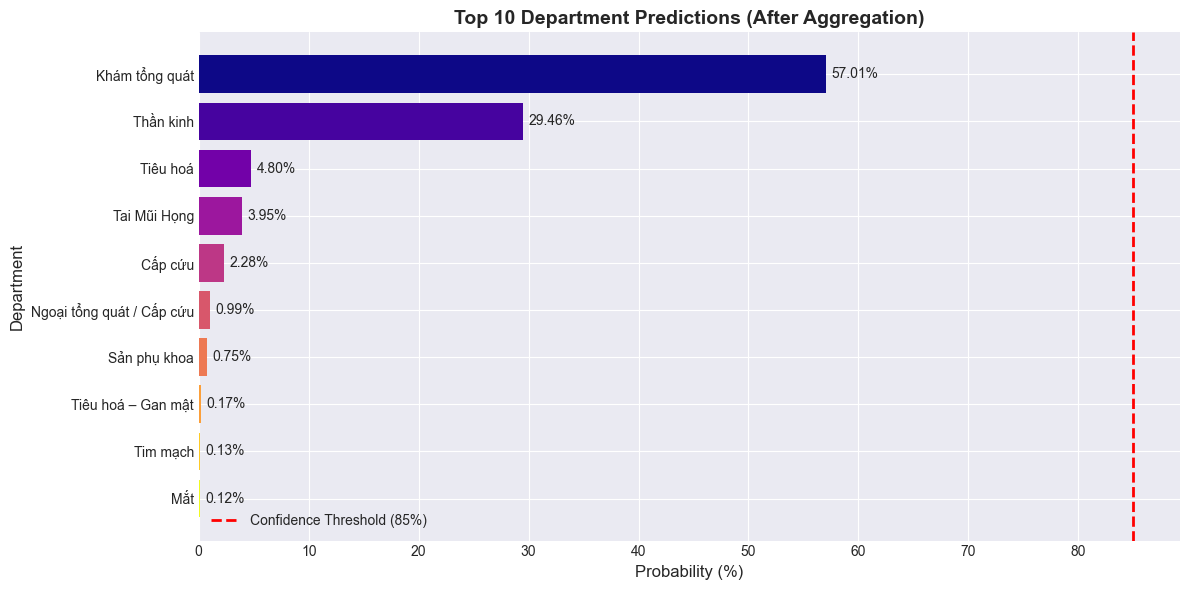

In [10]:
# Visualize department probabilities
fig, ax = plt.subplots(figsize=(12, 6))

depts = [dept_hyp.department_name for dept_hyp in session.current_departments[:10]]
dept_probs = [dept_hyp.probability*100 for dept_hyp in session.current_departments[:10]]

colors = plt.cm.plasma(np.linspace(0, 1, 10))
bars = ax.barh(depts, dept_probs, color=colors)

ax.set_xlabel('Probability (%)', fontsize=12)
ax.set_ylabel('Department', fontsize=12)
ax.set_title('Top 10 Department Predictions (After Aggregation)', fontsize=14, fontweight='bold')
ax.invert_yaxis()

# Add value labels
for bar, prob in zip(bars, dept_probs):
    ax.text(prob + 0.5, bar.get_y() + bar.get_height()/2, 
            f'{prob:.2f}%', va='center', fontsize=10)

# Add threshold line
ax.axvline(x=85, color='red', linestyle='--', linewidth=2, label='Confidence Threshold (85%)')
ax.legend()

plt.tight_layout()
plt.show()

---
## Step 3: Active Questioning (Department-Based)

Since no department has >85% confidence, the system will ask questions to discriminate between departments.

In [9]:
# Display first question
if first_question:
    print(" First Question:")
    print(f"   Q: {first_question.question_text}")
    print(f"   Symptom: {first_question.symptom_name}")
    print(f"   Reason: {first_question.reason}")
    print(f"   Information gain: {first_question.expected_info_gain:.4f}")
else:
    print(" No questions needed - confidence already high enough!")

 First Question:
   Q: Cho tôi hỏi, bạn có đau bụng dữ dội không?
   Symptom: đau bụng dữ dội
   Reason: Giúp phân biệt giữa khoa Khám tổng quát và Thần kinh
   Information gain: 0.0535


In [10]:
# Simulate answering questions
# For demonstration, we'll answer "YES" to the first 3 questions

questions_log = []
current_question = first_question
question_num = 1

# You can modify these answers to see different outcomes
SIMULATED_ANSWERS = [
    True,   # Answer YES to question 1
    True,   # Answer YES to question 2
    True,   # Answer YES to question 3
    False,  # Answer NO to question 4
    True,   # Answer YES to question 5
]

print(" Simulating Question-Answer Flow:")
print("="*80)

while current_question and not session.is_complete and question_num <= len(SIMULATED_ANSWERS):
    # Simulate answer
    has_symptom = SIMULATED_ANSWERS[question_num - 1]
    answer_text = "CÓ" if has_symptom else "KHÔNG"
    
    print(f"\n Question {question_num}:")
    print(f"   Q: {current_question.question_text}")
    print(f"   Symptom: {current_question.symptom_name}")
    print(f"   Patient answer: {answer_text}")
    
    # Log question
    questions_log.append({
        'question_num': question_num,
        'symptom': current_question.symptom_name,
        'question_text': current_question.question_text,
        'answer': answer_text,
        'info_gain': current_question.expected_info_gain
    })
    
    # Process answer
    session, next_question = ann_service.answer_department_question(
        session_id=session_id,
        symptom_name=current_question.symptom_name,
        has_symptom=has_symptom
    )
    
    # Show updated top 3 departments
    print(f"\n    Updated Department Probabilities:")
    for i, dept_hyp in enumerate(session.current_departments[:3], 1):
        print(f"      {i}. {dept_hyp.department_name}: {dept_hyp.probability*100:.2f}%")
    
    if session.is_complete:
        print(f"\n    Questioning complete!")
        #print(f"   Stop reason: {session.stop_reason}")
        break
    
    current_question = next_question
    question_num += 1

print("\n" + "="*80)
print(f" Total questions asked: {session.questions_asked}")

 Simulating Question-Answer Flow:

 Question 1:
   Q: Cho tôi hỏi, bạn có đau bụng dữ dội không?
   Symptom: đau bụng dữ dội
   Patient answer: CÓ

    Updated Department Probabilities:
      1. Tiêu hoá: 45.91%
      2. Ngoại tổng quát / Cấp cứu: 21.14%
      3. Khám tổng quát: 19.53%

 Question 2:
   Q: Cho tôi hỏi, bạn có táo bón không?
   Symptom: táo bón
   Patient answer: CÓ

    Updated Department Probabilities:
      1. Ngoại tổng quát / Cấp cứu: 99.63%
      2. Tiêu hoá: 0.25%
      3. Sản phụ khoa: 0.06%

    Questioning complete!

 Total questions asked: 2


In [11]:
# Display questions log
if questions_log:
    questions_df = pd.DataFrame(questions_log)
    print(" Questions Asked:")
    display(questions_df)

 Questions Asked:


,question_num,symptom,question_text,answer,info_gain
0,1,đau bụng dữ dội,"Cho tôi hỏi, bạn có đau bụng dữ dội không?",CÓ,0.053497
1,2,táo bón,"Cho tôi hỏi, bạn có táo bón không?",CÓ,0.160351


---
## Step 4: Final Results

In [13]:
# Display final results
final_dept = session.final_department

print("="*80)
print(" FINAL DEPARTMENT RECOMMENDATION")
print("="*80)

print(f"\n Department: {final_dept.department_name}")
print(f" Confidence: {final_dept.probability*100:.2f}%")
print(f" Questions asked: {session.questions_asked}")
#print(f" Stop reason: {session.stop_reason}")

print(f"\n Confidence Improvement:")
print(f"   Initial: {session.initial_confidence*100:.2f}%")
print(f"   Final: {final_dept.probability*100:.2f}%")
print(f"   Gain: +{(final_dept.probability - session.initial_confidence)*100:.2f}%")

if final_dept.contributing_diseases:
    top_disease, top_prob = final_dept.contributing_diseases[0]
    print(f"\n Top Disease within Department:")
    print(f"   Disease: {top_disease}")
    print(f"   Probability: {top_prob*100:.2f}%")

print("\n" + "="*80)

 FINAL DEPARTMENT RECOMMENDATION

 Department: Ngoại tổng quát / Cấp cứu
 Confidence: 99.63%
 Questions asked: 2

 Confidence Improvement:
   Initial: 57.01%
   Final: 99.63%
   Gain: +42.63%

 Top Disease within Department:
   Disease: tắc ruột
   Probability: 99.63%



In [14]:
# Show all diseases in final department (top 10)
print(f" All Diseases in {final_dept.department_name} Department (Top 10):")
print("="*80)

diseases_in_dept = []
for i, (disease, prob) in enumerate(final_dept.contributing_diseases[:10], 1):
    diseases_in_dept.append({
        'Rank': i,
        'Disease': disease,
        'Probability': f"{prob*100:.2f}%"
    })

diseases_in_dept_df = pd.DataFrame(diseases_in_dept)
diseases_in_dept_df

 All Diseases in Ngoại tổng quát / Cấp cứu Department (Top 10):


,Rank,Disease,Probability
0,1,tắc ruột,99.63%


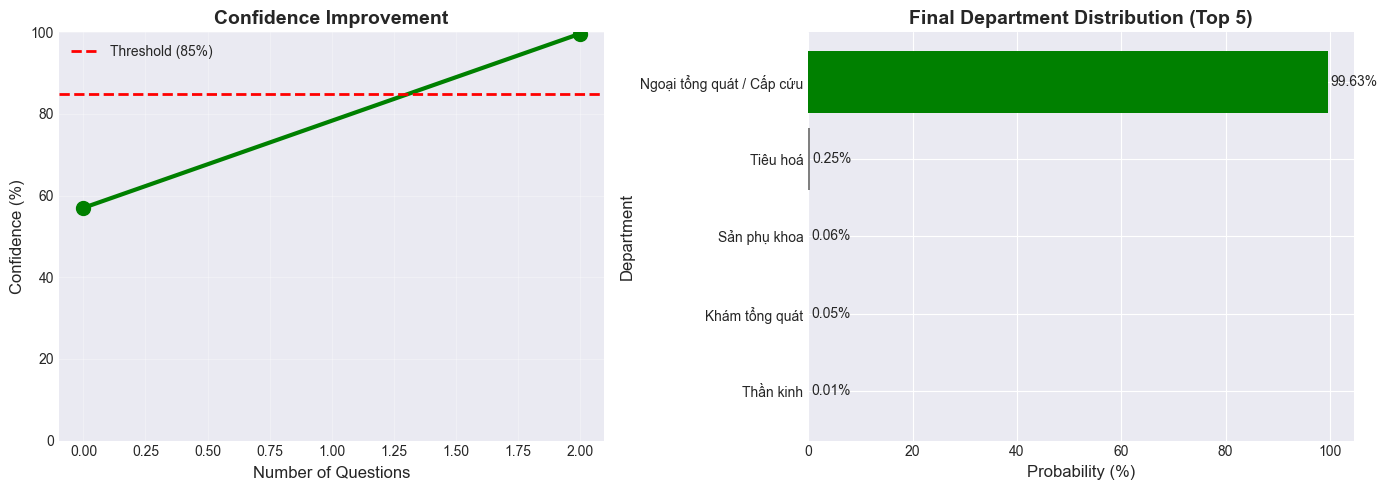

In [17]:
# Visualize confidence improvement
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Confidence progression
confidences = [session.initial_confidence * 100]
# Note: We'd need to track intermediate confidences during questioning for full progression
# For now, we'll show initial vs final
confidences.append(final_dept.probability * 100)

ax1.plot([0, session.questions_asked], confidences, marker='o', linewidth=3, markersize=10, color='green')
ax1.axhline(y=85, color='red', linestyle='--', linewidth=2, label='Threshold (85%)')
ax1.set_xlabel('Number of Questions', fontsize=12)
ax1.set_ylabel('Confidence (%)', fontsize=12)
ax1.set_title('Confidence Improvement', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0, 100)

# Right: Final department distribution
top_5_depts = [dept_hyp.department_name for dept_hyp in session.current_departments[:5]]
top_5_probs = [dept_hyp.probability*100 for dept_hyp in session.current_departments[:5]]

colors_final = ['green' if dept == final_dept.department_name else 'gray' for dept in top_5_depts]
bars = ax2.barh(top_5_depts, top_5_probs, color=colors_final)
ax2.set_xlabel('Probability (%)', fontsize=12)
ax2.set_ylabel('Department', fontsize=12)
ax2.set_title('Final Department Distribution (Top 5)', fontsize=14, fontweight='bold')
ax2.invert_yaxis()

# Add value labels
for bar, prob in zip(bars, top_5_probs):
    ax2.text(prob + 0.5, bar.get_y() + bar.get_height()/2, 
            f'{prob:.2f}%', va='center', fontsize=10)

plt.tight_layout()
plt.show()